# Cyclone Rapid-Intensification (RI) Predictor
**Problem:** Will a Bay of Bengal / Arabian Sea cyclone gain **>= 30 kt wind in the next 24 hours?** (standard RI cutoff)

**Dataset:** IMD RSMC New Delhi - *Best Tracks Data 1982-2026* (parsed using the `imdtrack` library)

**Models:** Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, SVM

In [1]:
# run this once (in Colab / Jupyter). Needs internet.
!pip install imdtrack openpyxl -q

## 1. Load the data

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import imdtrack as imd
import warnings
warnings.filterwarnings("ignore")

# download the IMD xlsx from the IMD website and parse it
try:
    bt = imd.load(source="imd")
except Exception as e:
    # if the IMD website is slow / blocked, use the already parsed copy
    print("IMD link did not work, using parsed copy instead:", e)
    bt = imd.load()

df = bt.observations.copy()   # one row = one fix (position + intensity at a time)

print("------------------------------------------------------------")
df.info()
print("------------------------------------------------------------")
print(df.describe())

------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7585 entries, 0 to 7584
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   storm_id       7585 non-null   object        
 1   year           7585 non-null   int64         
 2   serial         7585 non-null   int64         
 3   basin          7585 non-null   category      
 4   name           3111 non-null   object        
 5   time           7585 non-null   datetime64[ns]
 6   time_resolved  7585 non-null   datetime64[ns]
 7   lat            7584 non-null   float64       
 8   lon            7572 non-null   float64       
 9   ci_no          5862 non-null   float64       
 10  pressure       6816 non-null   float64       
 11  wind           7363 non-null   float64       
 12  pressure_drop  7080 non-null   float64       
 13  oci            499 non-null    float64       
 14  oci_diamete

In [3]:
df.head(10)

,storm_id,year,serial,basin,name,time,time_resolved,lat,lon,ci_no,pressure,wind,pressure_drop,oci,oci_diameter,grade,step,pos_suspect,date_suspect
0,1982-001,1982,1,BOB,None,1982-05-01 03:00:00,1982-05-01 03:00:00,14.0,82.5,1.5,NaN,25.0,3.000000,NaN,NaN,D,0,False,False
1,1982-001,1982,1,BOB,None,1982-05-01 06:00:00,1982-05-01 06:00:00,14.5,82.5,2.0,NaN,30.0,5.000000,NaN,NaN,DD,1,False,False
2,1982-001,1982,1,BOB,None,1982-05-01 12:00:00,1982-05-01 12:00:00,15.0,82.0,2.5,NaN,35.0,6.000000,NaN,NaN,CS,2,False,False
3,1982-001,1982,1,BOB,None,1982-05-01 18:00:00,1982-05-01 18:00:00,15.5,82.5,2.5,NaN,40.0,8.000000,NaN,NaN,CS,3,False,False
4,1982-001,1982,1,BOB,None,1982-05-02 00:00:00,1982-05-02 00:00:00,16.0,83.0,3.0,NaN,45.0,10.000000,NaN,NaN,CS,4,False,False
5,1982-001,1982,1,BOB,None,1982-05-02 03:00:00,1982-05-02 03:00:00,16.5,83.5,3.0,NaN,45.0,10.042650,NaN,NaN,CS,5,False,False
6,1982-001,1982,1,BOB,None,1982-05-02 06:00:00,1982-05-02 06:00:00,16.5,84.0,3.5,NaN,50.0,12.398334,NaN,NaN,SCS,6,False,False
7,1982-001,1982,1,BOB,None,1982-05-02 12:00:00,1982-05-02 12:00:00,16.5,84.5,3.5,NaN,55.0,15.001984,NaN,NaN,SCS,7,False,False
8,1982-001,1982,1,BOB,None,1982-05-02 18:00:00,1982-05-02 18:00:00,17.0,85.0,3.5,NaN,55.0,15.001984,NaN,NaN,SCS,8,False,False
9,1982-001,1982,1,BOB,None,1982-05-03 00:00:00,1982-05-03 00:00:00,17.0,86.0,3.5,NaN,60.0,17.853600,NaN,NaN,SCS,9,False,False


## 2. Data cleaning

In [4]:
# some dates are day/month swapped in the raw sheet, the library flags them
for c in ['pos_suspect', 'date_suspect']:
    if c in df.columns:
        print(c, "->", df[c].sum(), "suspect rows")

# fix the swapped dates
bt = bt.clean(fix_dates=True)
df = bt.observations.copy()
print("shape after cleaning:", df.shape)

pos_suspect -> 2 suspect rows
date_suspect -> 203 suspect rows
shape after cleaning: (7583, 19)


In [5]:
# make sure data types are correct
df['time'] = pd.to_datetime(df['time'])
for col in ['lat', 'lon', 'ci_no', 'pressure', 'wind', 'pressure_drop']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['grade'] = df['grade'].astype(str)
df['basin'] = df['basin'].astype(str)

# sort in time order inside each storm (very important for the 24h label)
df = df.drop_duplicates(subset=['storm_id', 'time'])
df = df.sort_values(['storm_id', 'time']).reset_index(drop=True)

df['year'] = df['time'].dt.year
df['month'] = df['time'].dt.month
df['decade'] = df['year'] // 10 * 10

# days since the storm started (used for life cycle graphs)
df['days_since_start'] = (df['time'] - df.groupby('storm_id')['time'].transform('min')).dt.total_seconds() // 86400

print(df.isnull().sum())
print("-------------------------")
# pressure is missing mostly in older years, so we do NOT fill it with 0
# (0 hPa is a wrong value). We will fill with median later.
print((df.groupby(df['year'] // 10 * 10)['pressure'].apply(lambda x: x.isnull().mean() * 100)).round(1))

storm_id               0
year                   0
serial                 0
basin                  0
name                4456
time                   0
time_resolved          0
lat                    1
lon                   13
ci_no               1709
pressure             756
wind                 210
pressure_drop        493
oci                 7065
oci_diameter        7065
grade                  0
step                   0
pos_suspect            0
date_suspect           0
month                  0
decade                 0
days_since_start       0
dtype: int64
-------------------------
year
1980    77.4
1990    17.5
2000     1.1
2010     0.1
2020     0.0
Name: pressure, dtype: float64


## 3. Basic analysis (EDA)

In [6]:
# storm level table (1 row = 1 cyclone)
storm_stats = df.groupby('storm_id').agg(
    name=('name', 'first'),
    year=('year', 'first'),
    decade=('decade', 'first'),
    month=('month', 'first'),
    basin=('basin', 'first'),
    fixes=('time', 'count'),
    start=('time', 'min'),
    end=('time', 'max'),
    lat_start=('lat', 'first'),
    lon_start=('lon', 'first'),
    max_wind=('wind', 'max'),
    min_pressure=('pressure', 'min')
)
storm_stats['duration_days'] = (storm_stats['end'] - storm_stats['start']).dt.total_seconds() / 86400

print("Total storms:", len(storm_stats))
print("Total fixes :", len(df))
print("-------------------------")

# strongest cyclones
top_storms = storm_stats.sort_values(by='max_wind', ascending=False).head(15).copy()
print(top_storms[['name', 'year', 'basin', 'max_wind', 'min_pressure']])

Total storms: 425
Total fixes : 7564
-------------------------
             name  year basin  max_wind  min_pressure
storm_id                                             
1999-007     None  1999   BOB     140.0         912.0
2020-001   AMPHAN  2020   BOB     130.0         920.0
2019-007    KYAAR  2019   ARB     130.0         922.0
1990-001     None  1990   BOB     127.0         920.0
2007-003     GONU  2007   ARB     127.0         920.0
1991-001     None  1991   BOB     127.0         918.0
2023-002    MOCHA  2023   BOB     115.0         938.0
1989-001     None  1989   BOB     115.0           NaN
1984-005     None  1984   BOB     115.0           NaN
1994-002     None  1994   BOB     115.0         940.0
1989-008     None  1989   BOB     115.0           NaN
2007-010     SIDR  2007   BOB     115.0         944.0
2015-010  CHAPALA  2015   ARB     115.0         940.0
2001-001     None  2001   ARB     115.0         932.0
2013-005  PHAILIN  2013   BOB     115.0         940.0


In [7]:
# basin wise stats
basin_stats = storm_stats.groupby('basin').agg(
    storms=('max_wind', 'count'),
    avg_max_wind=('max_wind', 'mean'),
    highest_wind=('max_wind', 'max'),
    avg_duration_days=('duration_days', 'mean')
)
print(basin_stats)
print("-------------------------")

# grade wise count
print(df['grade'].value_counts())

# order of IMD grades (weak to strong), used in many graphs below
order = ['D', 'DD', 'CS', 'SCS', 'VSCS', 'ESCS', 'SuCS']
order = [g for g in order if g in df['grade'].unique()]

# helper: make a nice label like "AMPHAN (2020)"
def make_label(t):
    nm = t['name'].fillna('').astype(str).str.strip()
    nm = nm.where(nm != '', t.index.to_series())
    return nm + " (" + t['year'].astype(str) + ")"

       storms  avg_max_wind  highest_wind  avg_duration_days
basin                                                       
ARB        98     47.704082         130.0           7.308673
BOB       291     43.704467         140.0           3.104739
LAND       34     25.882353          40.0           2.197917
-------------------------
grade
D       2768
DD      1630
CS      1592
SCS      627
VSCS     562
ESCS     313
SuCS      40
nan       32
Name: count, dtype: int64


### Graph 1: Horizontal bar - strongest cyclones

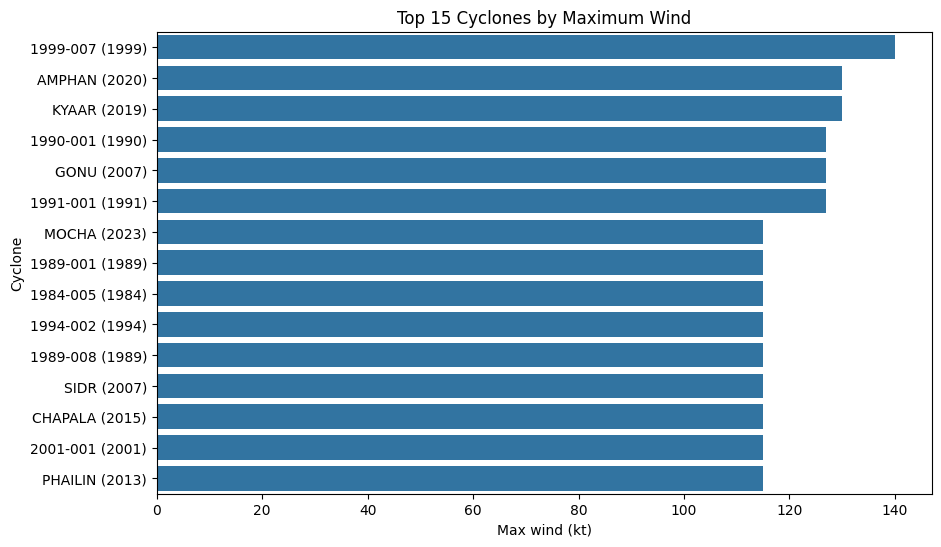

In [8]:
# Objective: which cyclones had the highest wind speed
top_storms['label'] = make_label(top_storms)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_storms['max_wind'], y=top_storms['label'])

plt.title("Top 15 Cyclones by Maximum Wind")
plt.xlabel("Max wind (kt)")
plt.ylabel("Cyclone")
plt.show()

### Graph 2: Lollipop chart - lowest central pressure

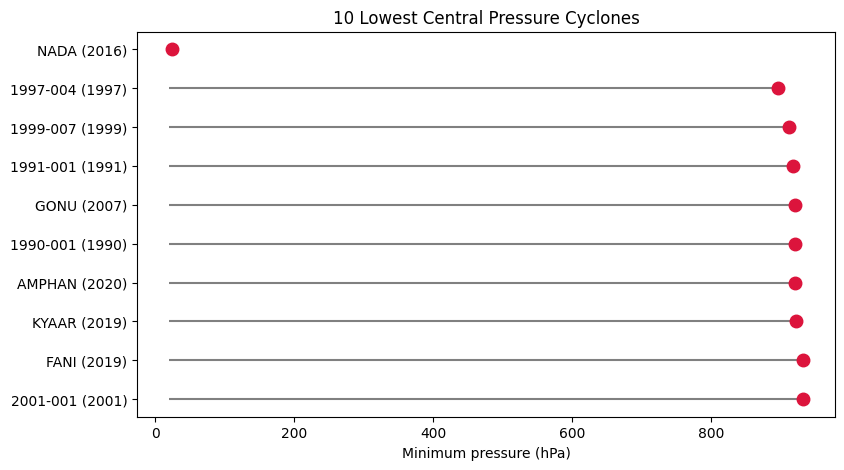

In [9]:
# Objective: deepest cyclones (low pressure = very intense)
low = storm_stats.dropna(subset=['min_pressure']).sort_values('min_pressure').head(10).copy()
low['label'] = make_label(low)

plt.figure(figsize=(9, 5))
y_pos = range(len(low))
plt.hlines(y=y_pos, xmin=low['min_pressure'].min() - 5, xmax=low['min_pressure'], color='gray')
plt.plot(low['min_pressure'], y_pos, 'o', color='crimson', markersize=9)
plt.yticks(y_pos, low['label'])
plt.gca().invert_yaxis()

plt.title("10 Lowest Central Pressure Cyclones")
plt.xlabel("Minimum pressure (hPa)")
plt.show()

### Graph 3: Heatmap - correlation

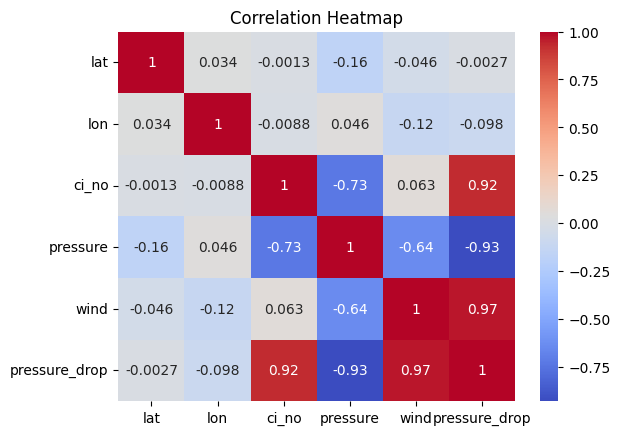

In [10]:
# Objective: check which numeric columns are related
num_cols = ['lat', 'lon', 'ci_no', 'pressure', 'wind', 'pressure_drop']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()
# wind has strong +ve relation with CI number and pressure drop, -ve with pressure

### Graph 4: Line plot - cyclones per year

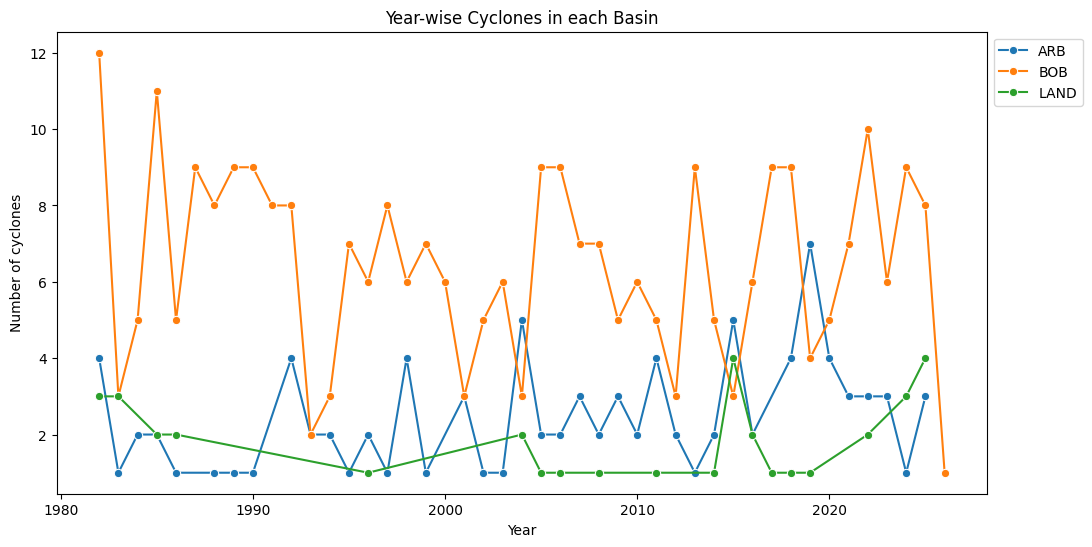

In [11]:
# Objective: is the number of cyclones increasing with years
storms_year = storm_stats.groupby(['year', 'basin']).size().reset_index(name='storms')

plt.figure(figsize=(12, 6))
sns.lineplot(data=storms_year, x='year', y='storms', hue='basin', marker='o')

plt.title("Year-wise Cyclones in each Basin")
plt.xlabel("Year")
plt.ylabel("Number of cyclones")
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

### Graph 5: Polar bar chart - cyclone season

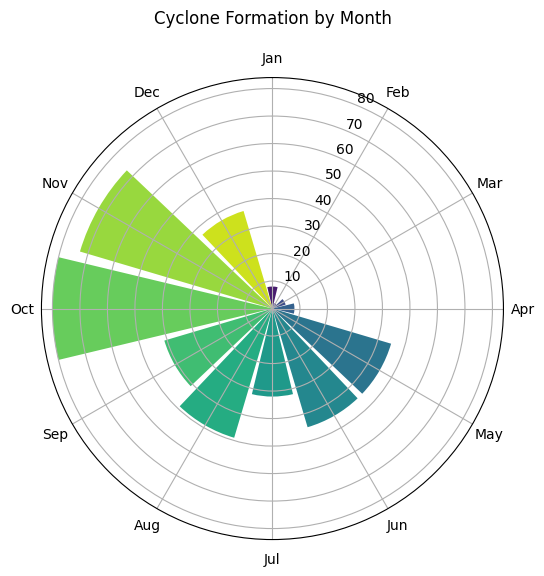

In [12]:
# Objective: which months have cyclones (circular chart = 12 months)
month_count = storm_stats['month'].value_counts().reindex(range(1, 13), fill_value=0)
angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)

plt.figure(figsize=(6, 6))
ax = plt.subplot(111, polar=True)
ax.bar(angles, month_count.values, width=2 * np.pi / 12 * 0.9, color=sns.color_palette("viridis", 12))
ax.set_xticks(angles)
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

plt.title("Cyclone Formation by Month", y=1.1)
plt.show()
# two peaks: April-May (pre monsoon) and Oct-Dec (post monsoon)

### Graph 6: Stacked bar - intensity grades by decade

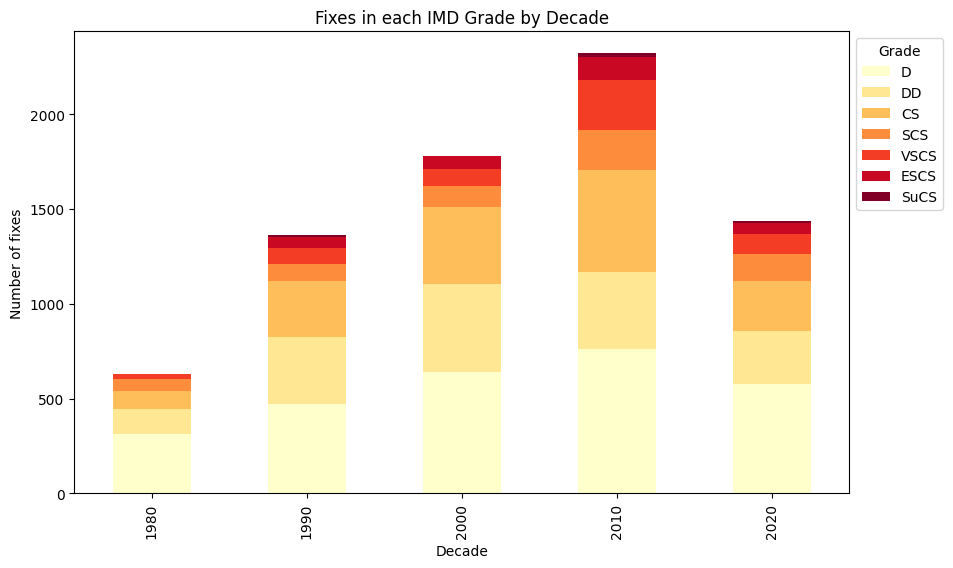

In [13]:
# Objective: are strong cyclones increasing in recent decades
grade_decade = pd.crosstab(df['decade'], df['grade'])[order]

grade_decade.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='YlOrRd')
plt.title("Fixes in each IMD Grade by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of fixes")
plt.legend(title='Grade', bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

### Graph 7: Histogram with KDE - wind speed

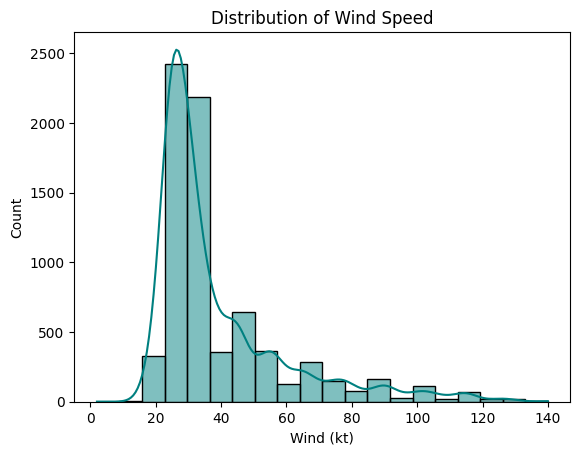

In [14]:
sns.histplot(df['wind'].dropna(), bins=20, kde=True, color='teal')
plt.title("Distribution of Wind Speed")
plt.xlabel("Wind (kt)")
plt.show()
# most fixes are weak (depression stage), strong winds are rare

### Graph 8: Donut chart - basin share

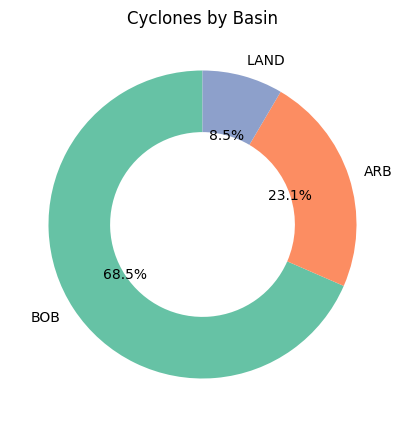

In [15]:
basin_count = storm_stats['basin'].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(basin_count.values, labels=basin_count.index, autopct='%1.1f%%', startangle=90,
        wedgeprops=dict(width=0.4), colors=sns.color_palette("Set2", len(basin_count)))
plt.title("Cyclones by Basin")
plt.show()

### Graph 9: Hexbin plot - pressure vs wind

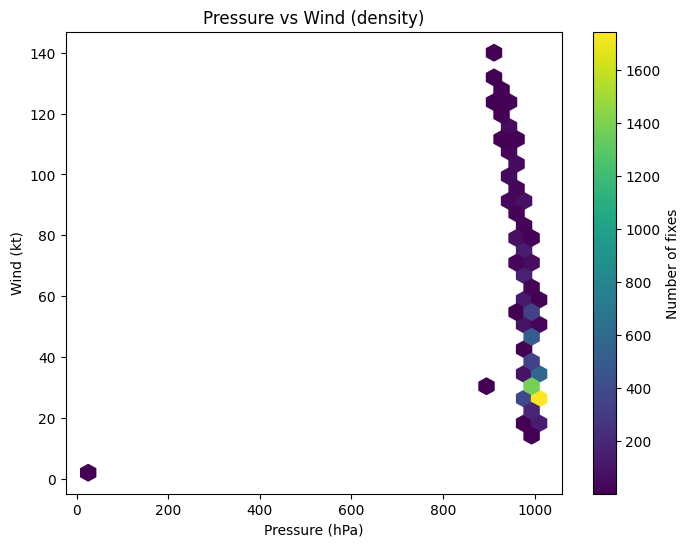

In [16]:
# Objective: relation of pressure and wind (hexbin shows density, better than plain scatter for 7000+ points)
tmp = df[['pressure', 'wind']].dropna()

plt.figure(figsize=(8, 6))
plt.hexbin(tmp['pressure'], tmp['wind'], gridsize=30, cmap='viridis', mincnt=1)
plt.colorbar(label='Number of fixes')

plt.title("Pressure vs Wind (density)")
plt.xlabel("Pressure (hPa)")
plt.ylabel("Wind (kt)")
plt.show()
# lower pressure = higher wind (negative relation)

### Graph 10: Violin plot - wind by basin

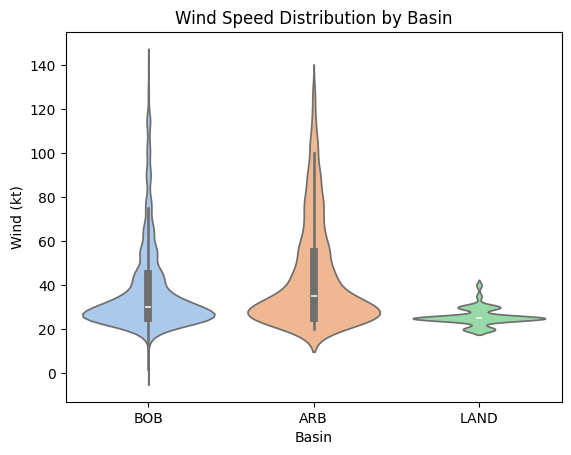

In [17]:
# Objective: compare wind speed spread in Bay of Bengal and Arabian Sea
sns.violinplot(data=df, x='basin', y='wind', palette='pastel')

plt.title("Wind Speed Distribution by Basin")
plt.xlabel("Basin")
plt.ylabel("Wind (kt)")
plt.show()

### Graph 11: 2D density (KDE) map - where cyclones form

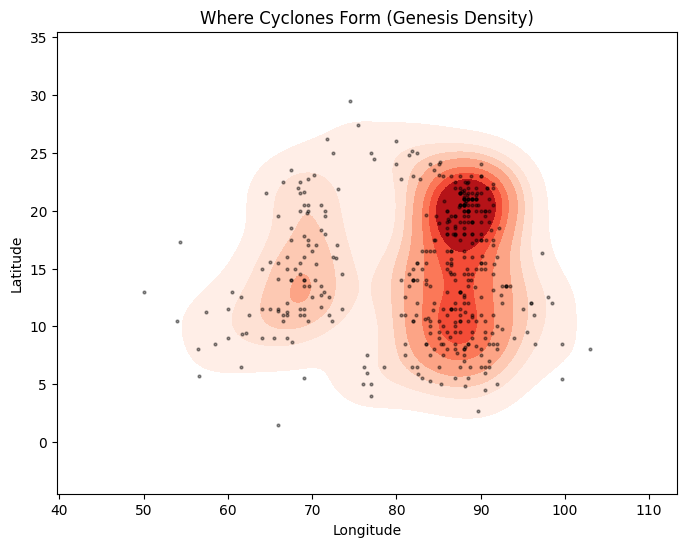

In [18]:
# Objective: genesis (starting) location of cyclones
gen = storm_stats.dropna(subset=['lon_start', 'lat_start'])

plt.figure(figsize=(8, 6))
sns.kdeplot(x=gen['lon_start'], y=gen['lat_start'], fill=True, cmap='Reds', levels=8)
plt.scatter(gen['lon_start'], gen['lat_start'], s=4, color='black', alpha=0.4)

plt.title("Where Cyclones Form (Genesis Density)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

### Graph 12: Scatter map - all positions coloured by wind

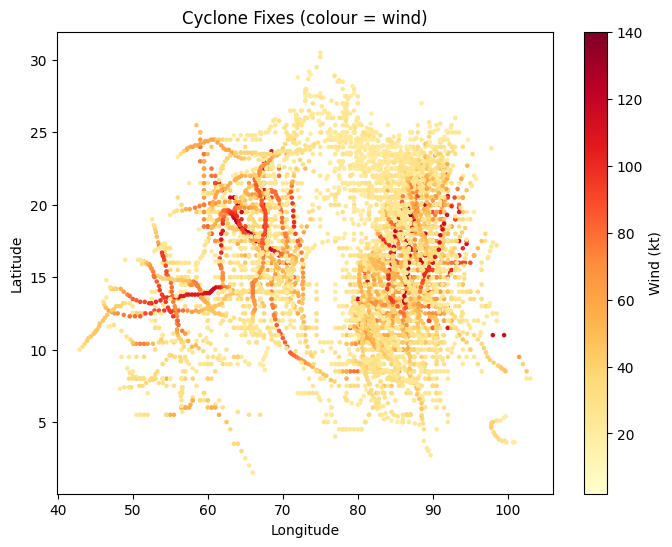

In [19]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(df['lon'], df['lat'], c=df['wind'], cmap='YlOrRd', s=5)
plt.colorbar(sc, label='Wind (kt)')

plt.title("Cyclone Fixes (colour = wind)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()
# strongest winds are at higher latitudes in the open sea, before landfall

### Graph 13: Average life cycle of a cyclone (line with spread)

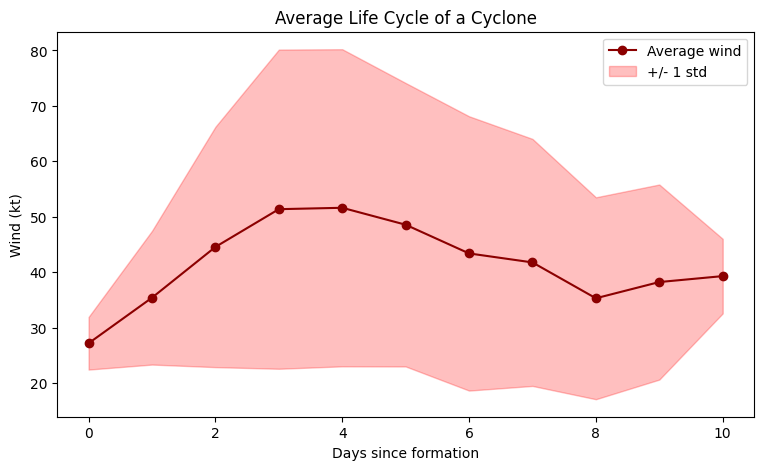

In [20]:
# Objective: how wind changes with age of the cyclone
life = df[df['days_since_start'] <= 10].groupby('days_since_start')['wind'].agg(['mean', 'std']).fillna(0)

plt.figure(figsize=(9, 5))
plt.plot(life.index, life['mean'], marker='o', color='darkred', label='Average wind')
plt.fill_between(life.index, life['mean'] - life['std'], life['mean'] + life['std'], alpha=0.25, color='red', label='+/- 1 std')

plt.title("Average Life Cycle of a Cyclone")
plt.xlabel("Days since formation")
plt.ylabel("Wind (kt)")
plt.legend()
plt.show()

### Graph 14: Multi-line - intensity history of the 5 strongest cyclones

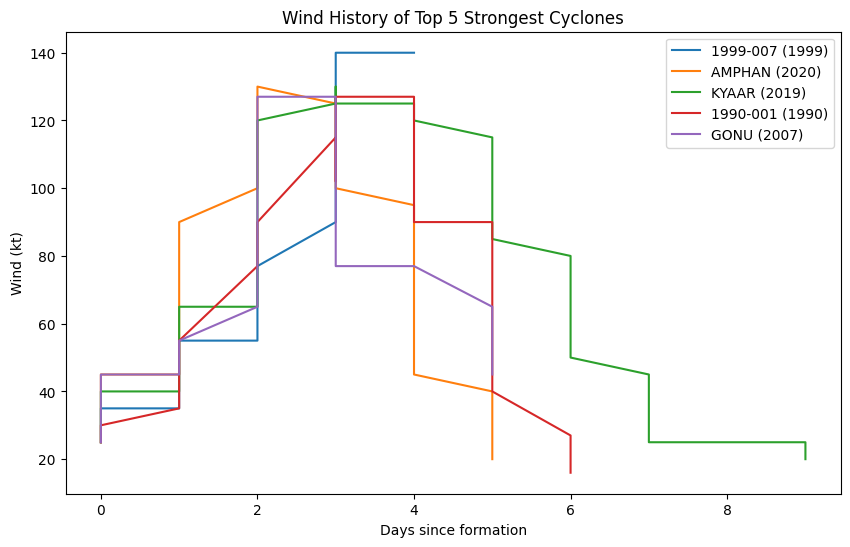

In [21]:
plt.figure(figsize=(10, 6))
for sid in top_storms.index[:5]:
    sub = df[df['storm_id'] == sid]
    plt.plot(sub['days_since_start'], sub['wind'], label=top_storms.loc[sid, 'label'])

plt.title("Wind History of Top 5 Strongest Cyclones")
plt.xlabel("Days since formation")
plt.ylabel("Wind (kt)")
plt.legend()
plt.show()
# strong cyclones show a sharp rise in wind = rapid intensification

### Graph 15: Box plot - max wind by decade

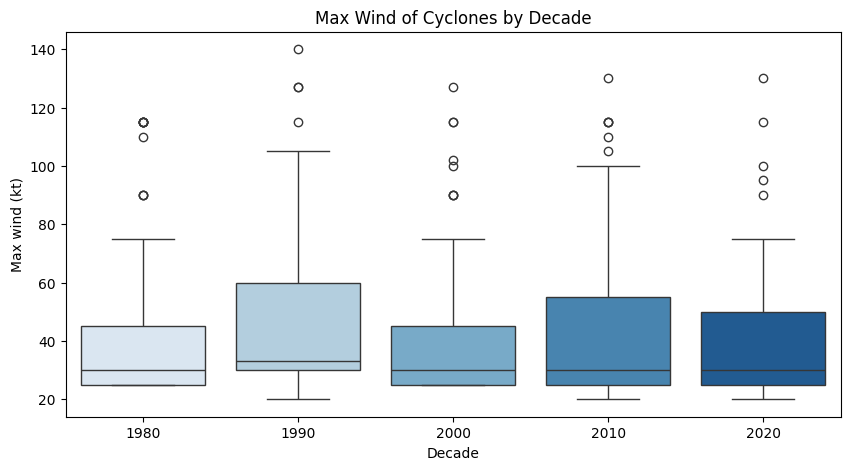

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=storm_stats, x='decade', y='max_wind', palette='Blues')

plt.title("Max Wind of Cyclones by Decade")
plt.xlabel("Decade")
plt.ylabel("Max wind (kt)")
plt.show()

In [23]:
# outlier detection using IQR method
q1 = storm_stats['max_wind'].quantile(0.25)
q3 = storm_stats['max_wind'].quantile(0.75)
IQR = q3 - q1
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR
outliers = storm_stats[(storm_stats['max_wind'] < lower_bound) | (storm_stats['max_wind'] > upper_bound)]
print("Q1, Q3, IQR:", q1, q3, IQR)
print("Number of outlier storms (very strong):", len(outliers))

Q1, Q3, IQR: 25.0 52.5 27.5
Number of outlier storms (very strong): 33


### Graph 16: Scatter plot with groups - duration vs strength

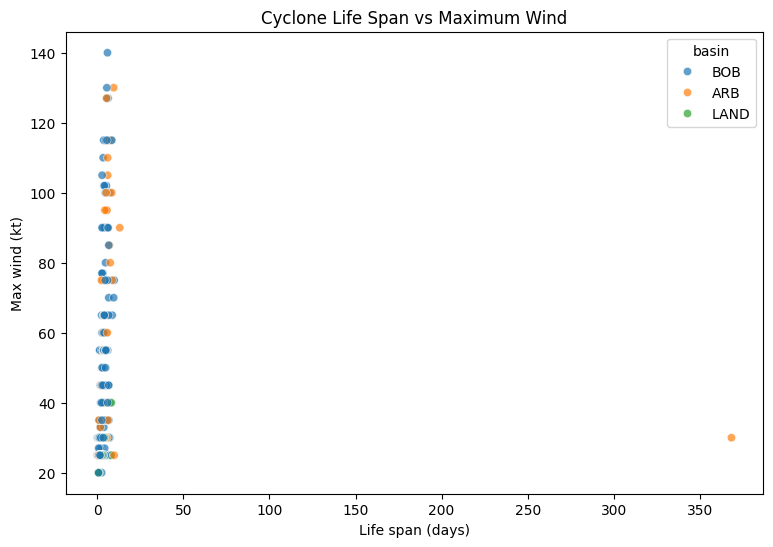

In [24]:
# Objective: do long lived cyclones become stronger
plt.figure(figsize=(9, 6))
sns.scatterplot(data=storm_stats, x='duration_days', y='max_wind', hue='basin', alpha=0.7)

plt.title("Cyclone Life Span vs Maximum Wind")
plt.xlabel("Life span (days)")
plt.ylabel("Max wind (kt)")
plt.show()

### Graph 17: ECDF plot - how many cyclones are weaker than a given wind

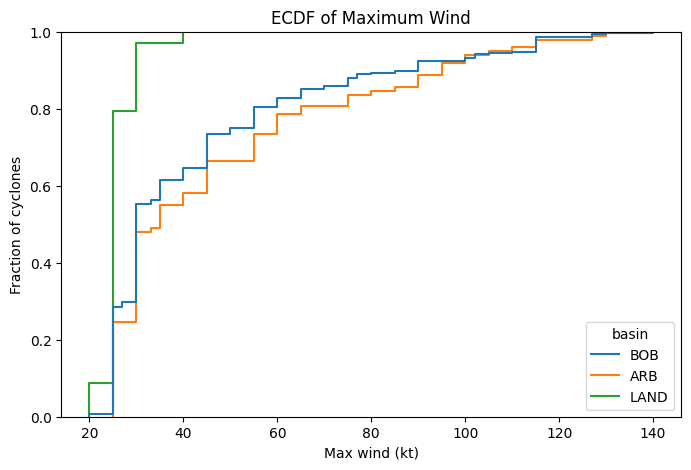

In [25]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=storm_stats, x='max_wind', hue='basin')

plt.title("ECDF of Maximum Wind")
plt.xlabel("Max wind (kt)")
plt.ylabel("Fraction of cyclones")
plt.show()
# example: read the y value at 64 kt to see what fraction never became a very severe cyclone

### Graph 18: Area chart - cumulative cyclones

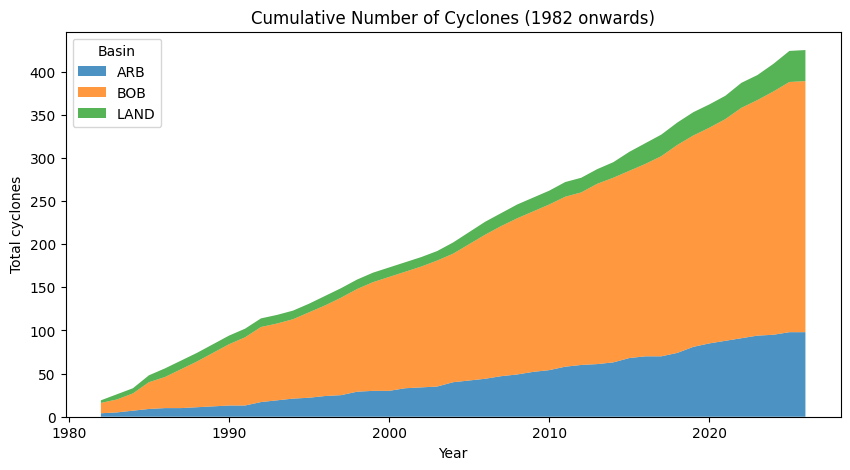

In [26]:
cum = storm_stats.groupby(['year', 'basin']).size().unstack(fill_value=0).cumsum()

plt.figure(figsize=(10, 5))
plt.stackplot(cum.index, cum.T.values, labels=cum.columns, alpha=0.8)

plt.title("Cumulative Number of Cyclones (1982 onwards)")
plt.xlabel("Year")
plt.ylabel("Total cyclones")
plt.legend(loc='upper left', title='Basin')
plt.show()

### Graph 19: Pair plot

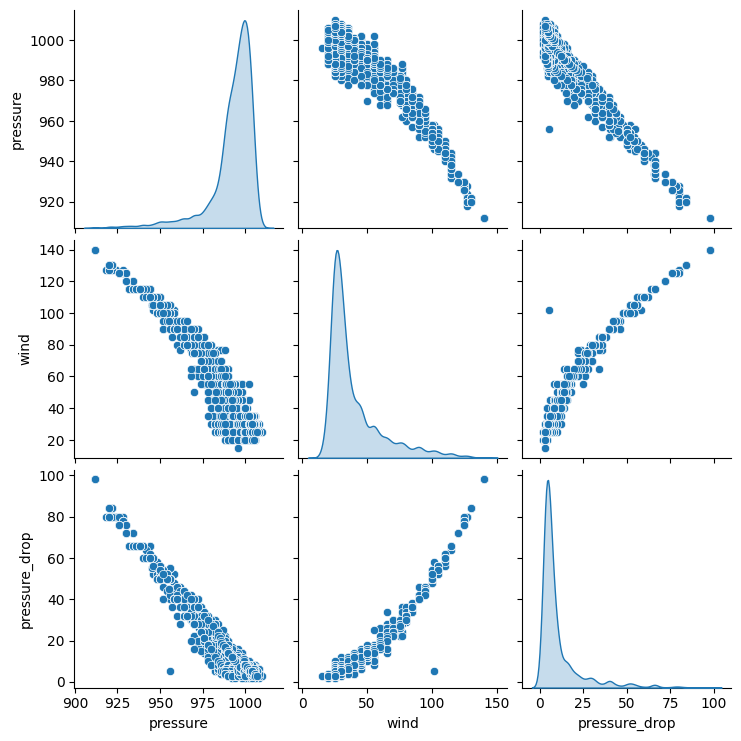

In [27]:
sns.pairplot(df[['pressure', 'wind', 'pressure_drop']].dropna(), diag_kind='kde')
plt.show()

## 4. Simple Linear Regression and Hypothesis Test

In [28]:
# 1. Predict wind from pressure drop using simple linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

lin_df = df[['pressure_drop', 'wind']].dropna()
x = lin_df[['pressure_drop']]
y = lin_df['wind']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=100)
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Intercept:", model.intercept_)
print("Slope    :", model.coef_)
print("R2 score :", r2_score(y_test, y_pred))
print("MSE      :", mean_squared_error(y_test, y_pred))

Intercept: 22.456433984946596
Slope    : [1.61089731]
R2 score : 0.9363973338801986
MSE      : 28.379859081257027


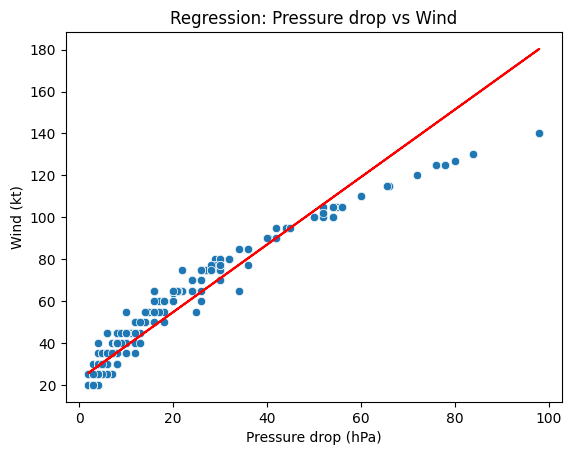

In [29]:
sns.scatterplot(x=x_test['pressure_drop'], y=y_test)
plt.plot(x_test, y_pred, color='red')

plt.title("Regression: Pressure drop vs Wind")
plt.xlabel("Pressure drop (hPa)")
plt.ylabel("Wind (kt)")
plt.show()

In [30]:
# 2. Two sample t-test
# H0: average max wind of Bay of Bengal storms = Arabian Sea storms
# H1: they are different
from scipy.stats import ttest_ind

bob = storm_stats[storm_stats['basin'] == 'BOB']['max_wind'].dropna()
arb = storm_stats[storm_stats['basin'] == 'ARB']['max_wind'].dropna()

print("BOB mean:", bob.mean(), " n =", len(bob))
print("ARB mean:", arb.mean(), " n =", len(arb))

t_stat, p_value = ttest_ind(bob, arb, equal_var=False)
print("t value:", t_stat)
print("p value:", p_value)

if p_value < 0.05:
    print("Reject H0: the two basins have different average max wind")
else:
    print("Fail to reject H0: no significant difference")

BOB mean: 43.70446735395189  n = 291
ARB mean: 47.704081632653065  n = 98
t value: -1.257099741609331
p value: 0.21056833074654382
Fail to reject H0: no significant difference


## 5. Make the target (Rapid Intensification)
Fixes are not equally spaced (03, 06, 12, 18, 00 UTC), so we cannot just use the *next row*.
For every fix we find the wind exactly **24 hours later** of the same storm.

**RI = 1** if (wind after 24h - wind now) >= 30 kt, else 0

In [31]:
d = df.dropna(subset=['wind']).copy()

# wind exactly 24 hours LATER (this is only for the label)
future = d[['storm_id', 'time', 'wind']].copy()
future['time'] = future['time'] - pd.Timedelta(hours=24)
future = future.rename(columns={'wind': 'wind_24h_later'})
d = d.merge(future, on=['storm_id', 'time'], how='left')

# wind exactly 24 hours BEFORE (past info, safe to use as a feature)
past = d[['storm_id', 'time', 'wind']].copy()
past['time'] = past['time'] + pd.Timedelta(hours=24)
past = past.rename(columns={'wind': 'wind_24h_before'})
d = d.merge(past, on=['storm_id', 'time'], how='left')

d['wind_change_24h'] = d['wind_24h_later'] - d['wind']
d['RI'] = (d['wind_change_24h'] >= 30).astype(int)

# keep only the rows where we know the future wind
data = d.dropna(subset=['wind_24h_later']).copy()

print("Rows with a 24h future:", len(data))
print("RI cases count:")
print(data['RI'].value_counts())
print("RI percentage:", round(data['RI'].mean() * 100, 2), "%")
print("Storms having at least one RI:", data[data['RI'] == 1]['storm_id'].nunique())

Rows with a 24h future: 4998
RI cases count:
RI
0    4695
1     303
Name: count, dtype: int64
RI percentage: 6.06 %
Storms having at least one RI: 66


### Graph 20: Bar chart with labels - class imbalance

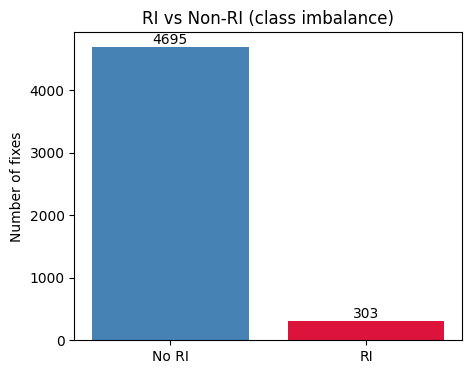

In [32]:
ri_count = data['RI'].value_counts().sort_index()

plt.figure(figsize=(5, 4))
bars = plt.bar(['No RI', 'RI'], ri_count.values, color=['steelblue', 'crimson'])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), int(b.get_height()), ha='center', va='bottom')

plt.title("RI vs Non-RI (class imbalance)")
plt.ylabel("Number of fixes")
plt.show()
# RI is rare, so accuracy alone is a bad metric. We will use recall, F1 and ROC-AUC.

### Graph 21: Histogram - 24 hour wind change with RI cutoff

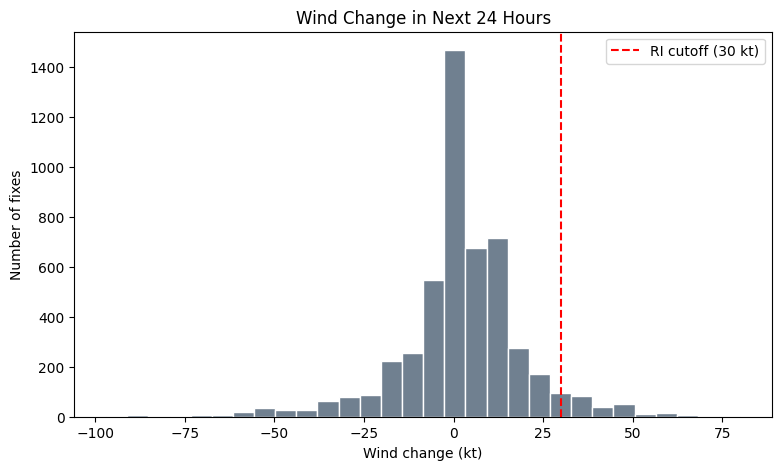

In [33]:
plt.figure(figsize=(9, 5))
plt.hist(data['wind_change_24h'], bins=30, color='slategray', edgecolor='white')
plt.axvline(30, color='red', linestyle='--', label='RI cutoff (30 kt)')

plt.title("Wind Change in Next 24 Hours")
plt.xlabel("Wind change (kt)")
plt.ylabel("Number of fixes")
plt.legend()
plt.show()

### Graph 22: Bar chart - RI chance for each grade

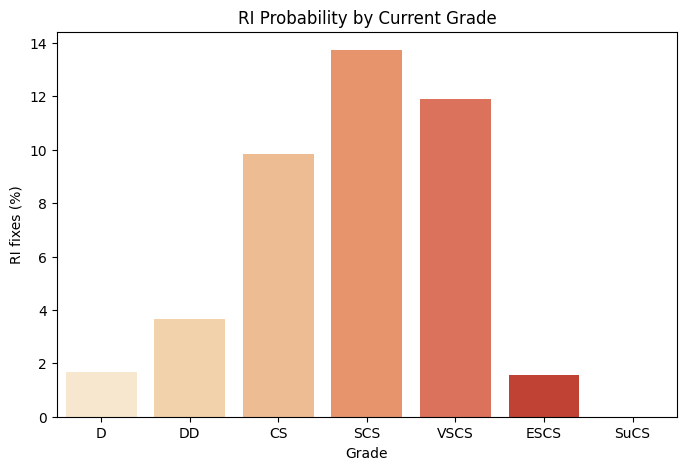

In [34]:
# Objective: at which intensity stage does RI happen most
ri_grade = (data.groupby('grade')['RI'].mean() * 100).reindex(order).dropna()

plt.figure(figsize=(8, 5))
sns.barplot(x=ri_grade.index, y=ri_grade.values, palette='OrRd')

plt.title("RI Probability by Current Grade")
plt.xlabel("Grade")
plt.ylabel("RI fixes (%)")
plt.show()

### Graph 23: Line plot - RI chance by month

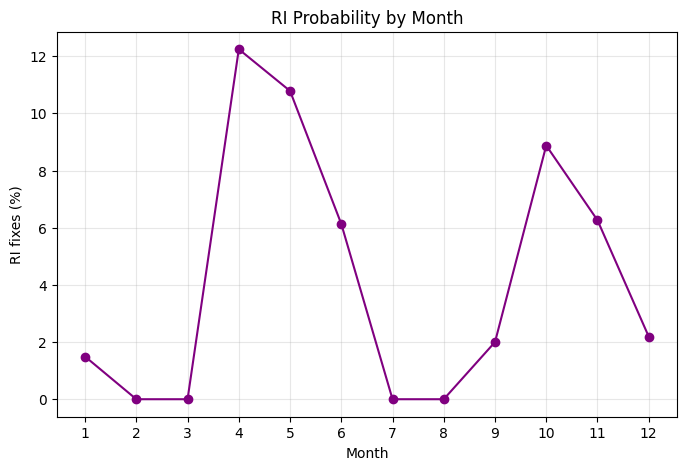

In [35]:
ri_month = (data.groupby('month')['RI'].mean() * 100)

plt.figure(figsize=(8, 5))
plt.plot(ri_month.index, ri_month.values, marker='o', color='purple')
plt.xticks(range(1, 13))

plt.title("RI Probability by Month")
plt.xlabel("Month")
plt.ylabel("RI fixes (%)")
plt.grid(alpha=0.3)
plt.show()

### Graph 24: Map - where RI happens

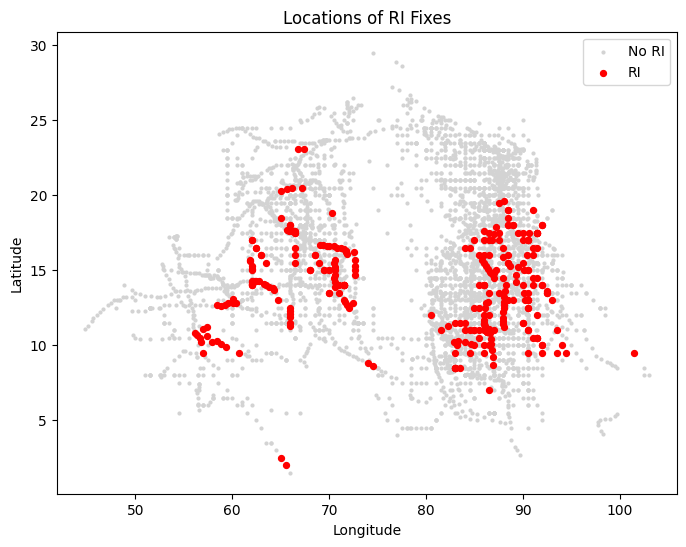

In [36]:
plt.figure(figsize=(8, 6))
no_ri = data[data['RI'] == 0]
ri = data[data['RI'] == 1]
plt.scatter(no_ri['lon'], no_ri['lat'], s=4, color='lightgray', label='No RI')
plt.scatter(ri['lon'], ri['lat'], s=18, color='red', label='RI')

plt.title("Locations of RI Fixes")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

### Graph 25: Violin plot - current wind for RI and non-RI

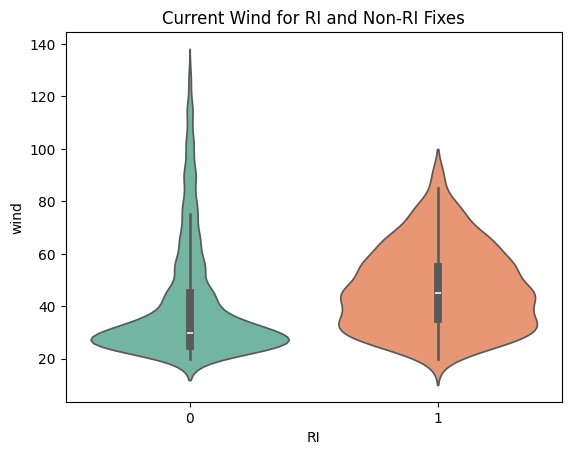

In [37]:
sns.violinplot(data=data, x='RI', y='wind', palette='Set2')
plt.title("Current Wind for RI and Non-RI Fixes")
plt.show()

## 6. Features and Train-Test split
**Important:** the label uses future rows, so we split **by storm** (not random rows).
Otherwise the same storm comes in both train and test = data leakage.

In [38]:
# change text columns to numbers
grade_map = {'D': 0, 'DD': 1, 'CS': 2, 'SCS': 3, 'VSCS': 4, 'ESCS': 5, 'SuCS': 6}
basin_map = {'BOB': 0, 'ARB': 1}

data['grade_code'] = data['grade'].map(grade_map)
data['basin_code'] = data['basin'].map(basin_map).fillna(2)
data['past_change'] = (data['wind'] - data['wind_24h_before']).fillna(0)

features = ['wind', 'pressure', 'pressure_drop', 'ci_no', 'lat', 'lon',
            'month', 'basin_code', 'grade_code', 'past_change']

X = data[features]
y = data['RI']
groups = data['storm_id']
print(X.isnull().sum())

wind               0
pressure         287
pressure_drop    177
ci_no            638
lat                1
lon                6
month              0
basin_code         0
grade_code         9
past_change        0
dtype: int64


In [39]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# split by storm (25% of storms go to test)
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train rows:", len(X_train), " RI in train:", y_train.sum())
print("Test rows :", len(X_test), " RI in test :", y_test.sum())
print("Storms in both train and test:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))   # must be 0

# fill missing values with median, then scale (fit on train only)
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train_s = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_s = scaler.transform(imputer.transform(X_test))

Train rows: 3864  RI in train: 214
Test rows : 1134  RI in test : 89
Storms in both train and test: 0


In [40]:
# helper function to print results of every model in the same way
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

results = {}
preds = {}

def show_results(name, y_test, y_pred, y_prob):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    print(name)
    print("Accuracy :", round(acc, 3))
    print("Precision:", round(prec, 3))
    print("Recall   :", round(rec, 3))
    print("F1 score :", round(f1, 3))
    print("ROC-AUC  :", round(auc, 3))
    print(classification_report(y_test, y_pred, zero_division=0))

    preds[name] = y_pred
    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1, 'ROC-AUC': auc}

## 7. Models

### Model 1: Logistic Regression

In [41]:
from sklearn.linear_model import LogisticRegression

# class_weight='balanced' because RI cases are very few
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train_s, y_train)

y_pred = lr.predict(X_test_s)
y_prob = lr.predict_proba(X_test_s)[:, 1]
show_results("Logistic Regression", y_test, y_pred, y_prob)

Logistic Regression
Accuracy : 0.647
Precision: 0.144
Recall   : 0.708
F1 score : 0.24
ROC-AUC  : 0.747
              precision    recall  f1-score   support

           0       0.96      0.64      0.77      1045
           1       0.14      0.71      0.24        89

    accuracy                           0.65      1134
   macro avg       0.55      0.67      0.50      1134
weighted avg       0.90      0.65      0.73      1134



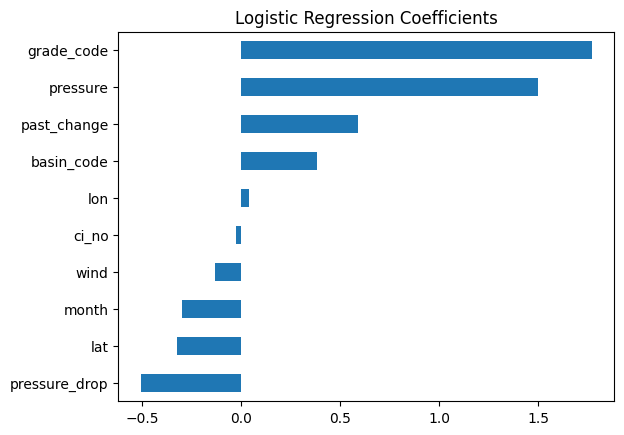

In [42]:
# which feature matters in logistic regression
coef = pd.Series(lr.coef_[0], index=features).sort_values()
coef.plot(kind='barh')
plt.title("Logistic Regression Coefficients")
plt.show()

### Model 2: Decision Tree

In [43]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight='balanced', random_state=42)
dt.fit(X_train_s, y_train)

y_pred = dt.predict(X_test_s)
y_prob = dt.predict_proba(X_test_s)[:, 1]
show_results("Decision Tree", y_test, y_pred, y_prob)

Decision Tree
Accuracy : 0.626
Precision: 0.155
Recall   : 0.843
F1 score : 0.261
ROC-AUC  : 0.737
              precision    recall  f1-score   support

           0       0.98      0.61      0.75      1045
           1       0.15      0.84      0.26        89

    accuracy                           0.63      1134
   macro avg       0.57      0.73      0.51      1134
weighted avg       0.91      0.63      0.71      1134



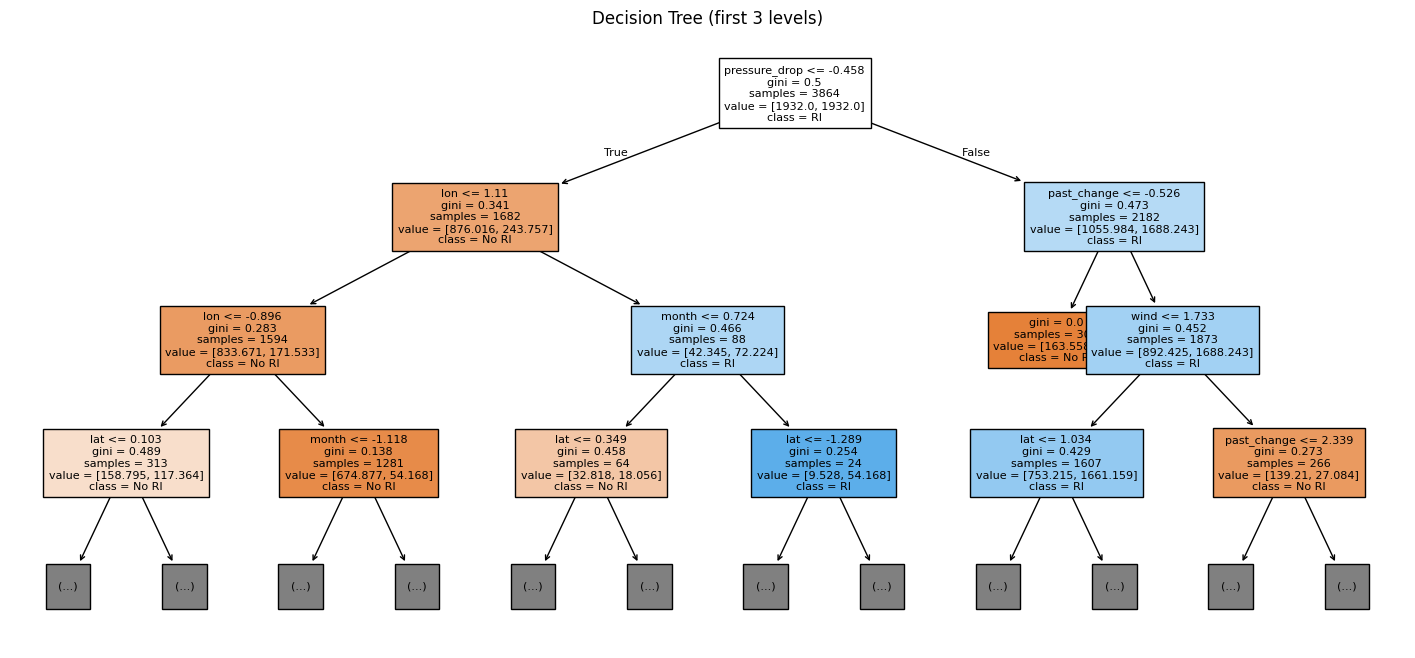

In [44]:
plt.figure(figsize=(18, 8))
plot_tree(dt, max_depth=3, feature_names=features, class_names=['No RI', 'RI'], filled=True, fontsize=8)
plt.title("Decision Tree (first 3 levels)")
plt.show()

### Model 3: Random Forest

In [45]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                            class_weight='balanced', random_state=42)
rf.fit(X_train_s, y_train)

y_pred = rf.predict(X_test_s)
y_prob = rf.predict_proba(X_test_s)[:, 1]
show_results("Random Forest", y_test, y_pred, y_prob)

Random Forest
Accuracy : 0.787
Precision: 0.222
Recall   : 0.685
F1 score : 0.335
ROC-AUC  : 0.815
              precision    recall  f1-score   support

           0       0.97      0.80      0.87      1045
           1       0.22      0.69      0.34        89

    accuracy                           0.79      1134
   macro avg       0.59      0.74      0.60      1134
weighted avg       0.91      0.79      0.83      1134



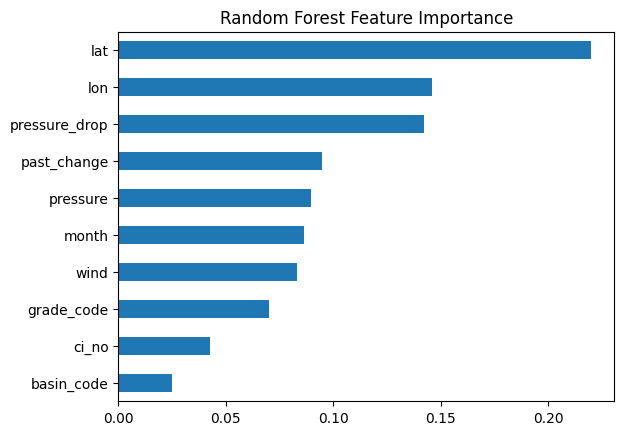

In [46]:
# feature importance
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind='barh')
plt.title("Random Forest Feature Importance")
plt.show()

### Model 4: Gradient Boosting

In [47]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# gradient boosting has no class_weight, so we give sample weights
sw = compute_sample_weight('balanced', y_train)

gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train_s, y_train, sample_weight=sw)

y_pred = gb.predict(X_test_s)
y_prob = gb.predict_proba(X_test_s)[:, 1]
show_results("Gradient Boosting", y_test, y_pred, y_prob)

Gradient Boosting
Accuracy : 0.821
Precision: 0.236
Recall   : 0.573
F1 score : 0.334
ROC-AUC  : 0.799
              precision    recall  f1-score   support

           0       0.96      0.84      0.90      1045
           1       0.24      0.57      0.33        89

    accuracy                           0.82      1134
   macro avg       0.60      0.71      0.62      1134
weighted avg       0.90      0.82      0.85      1134



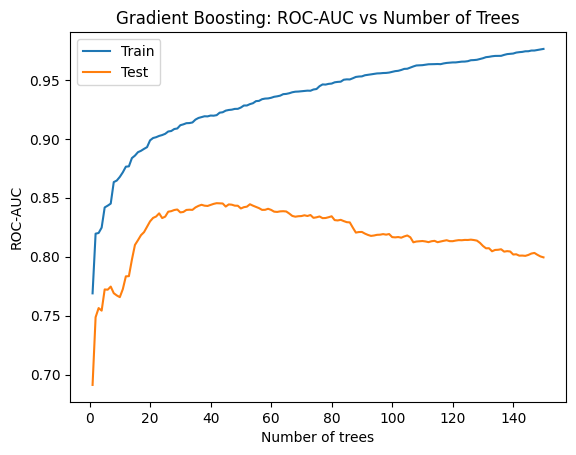

In [48]:
# Graph: how AUC changes as more trees are added (checks overfitting)
train_auc = [roc_auc_score(y_train, p[:, 1]) for p in gb.staged_predict_proba(X_train_s)]
test_auc = [roc_auc_score(y_test, p[:, 1]) for p in gb.staged_predict_proba(X_test_s)]

plt.plot(range(1, len(train_auc) + 1), train_auc, label='Train')
plt.plot(range(1, len(test_auc) + 1), test_auc, label='Test')
plt.title("Gradient Boosting: ROC-AUC vs Number of Trees")
plt.xlabel("Number of trees")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

### Model 5: SVM

In [49]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1, class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train_s, y_train)

y_pred = svm.predict(X_test_s)
y_prob = svm.predict_proba(X_test_s)[:, 1]
show_results("SVM", y_test, y_pred, y_prob)

SVM
Accuracy : 0.694
Precision: 0.164
Recall   : 0.708
F1 score : 0.266
ROC-AUC  : 0.769
              precision    recall  f1-score   support

           0       0.97      0.69      0.81      1045
           1       0.16      0.71      0.27        89

    accuracy                           0.69      1134
   macro avg       0.56      0.70      0.54      1134
weighted avg       0.90      0.69      0.76      1134



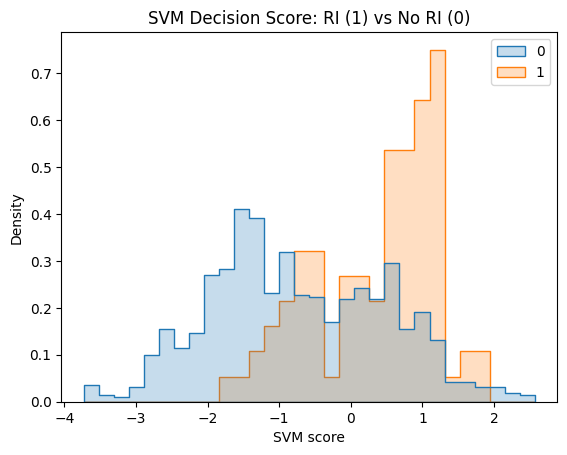

In [50]:
# Graph: SVM score for RI and non-RI fixes (good model = two humps far apart)
scores = svm.decision_function(X_test_s)
sns.histplot(x=scores, hue=y_test.values, stat='density', common_norm=False, element='step', bins=30)
plt.title("SVM Decision Score: RI (1) vs No RI (0)")
plt.xlabel("SVM score")
plt.show()

## 8. Compare all models

                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.647      0.144   0.708  0.240    0.747
Decision Tree           0.626      0.155   0.843  0.261    0.737
Random Forest           0.787      0.222   0.685  0.335    0.815
Gradient Boosting       0.821      0.236   0.573  0.334    0.799
SVM                     0.694      0.164   0.708  0.266    0.769


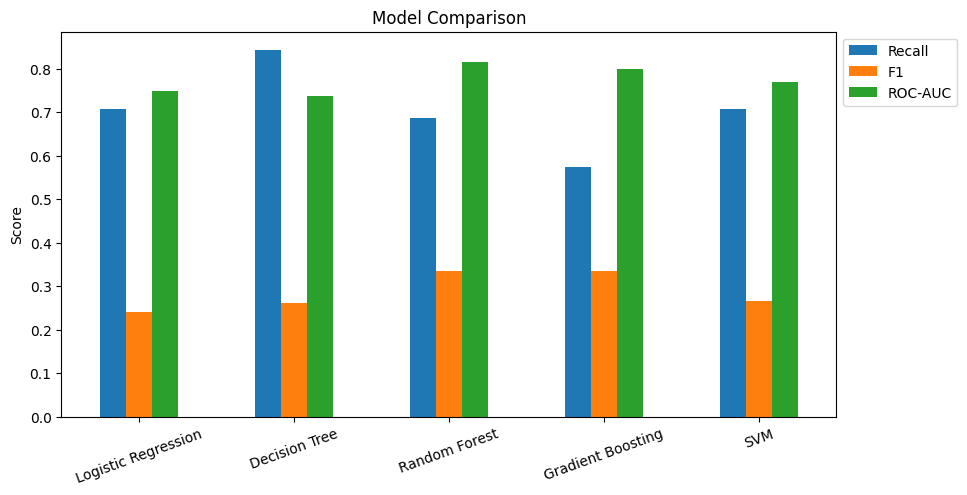

In [51]:
results_df = pd.DataFrame(results).T
print(results_df.round(3))

results_df[['Recall', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

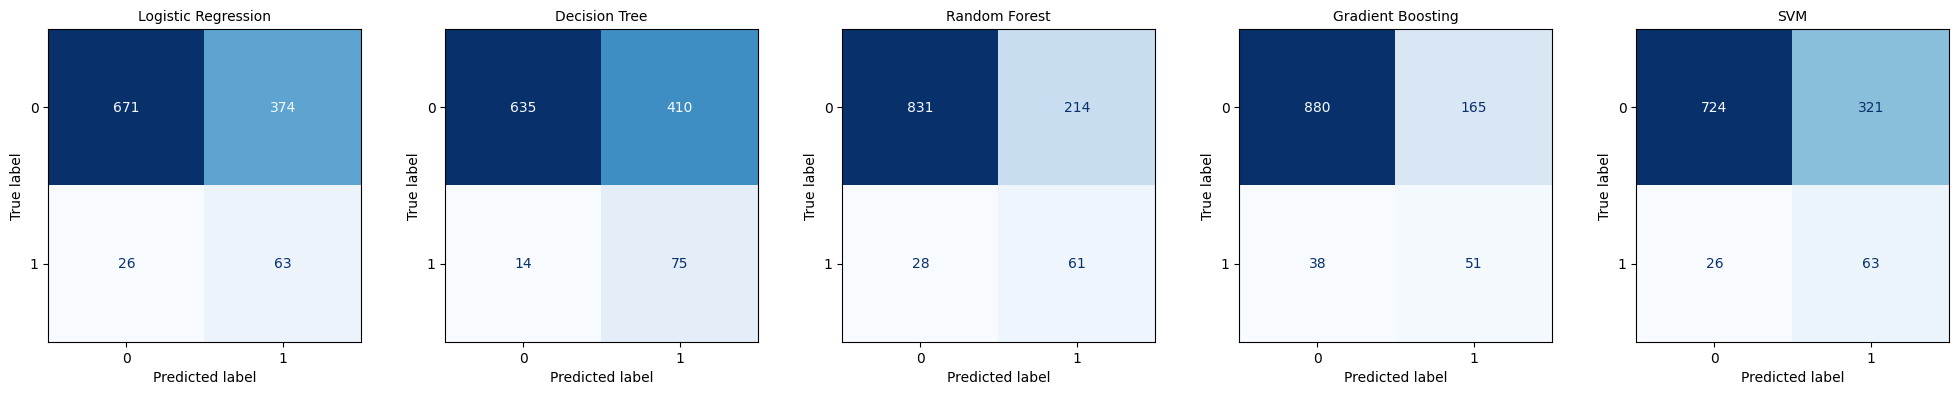

In [52]:
# confusion matrix of all 5 models side by side
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

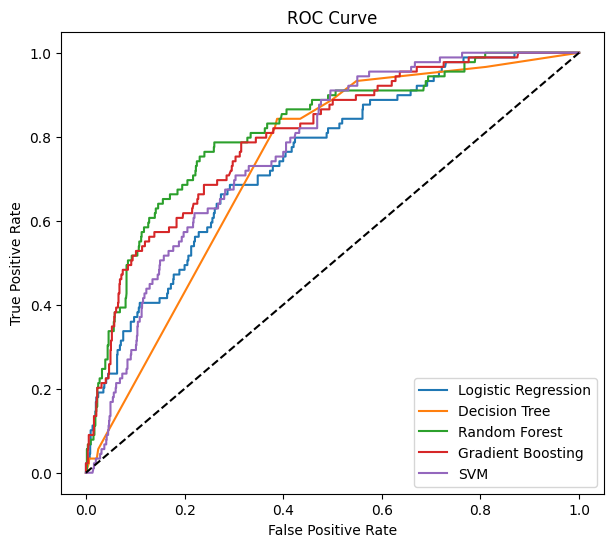

In [53]:
# ROC curve of all models
from sklearn.metrics import roc_curve

all_models = {'Logistic Regression': lr, 'Decision Tree': dt, 'Random Forest': rf,
              'Gradient Boosting': gb, 'SVM': svm}

plt.figure(figsize=(7, 6))
for name, m in all_models.items():
    prob = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

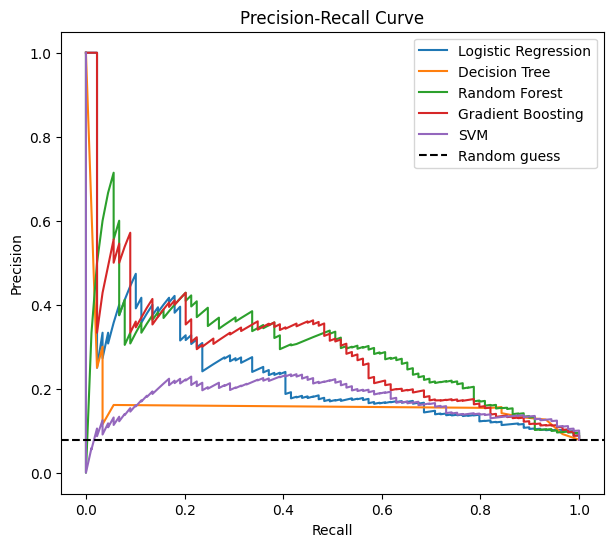

In [54]:
# Precision-Recall curve (better than ROC when positive class is rare)
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(7, 6))
for name, m in all_models.items():
    prob = m.predict_proba(X_test_s)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, prob)
    plt.plot(rec, prec, label=name)

plt.axhline(y_test.mean(), color='k', linestyle='--', label='Random guess')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

## 9. GroupKFold cross validation
One test split can be lucky or unlucky because RI cases are so few.
So we repeat with 5 folds, where each storm stays in only one fold.

In [55]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone

gkf = GroupKFold(n_splits=5)
cv_results = {name: {'F1': [], 'ROC-AUC': []} for name in all_models}

for tr, te in gkf.split(X, y, groups):
    Xtr, Xte = X.iloc[tr], X.iloc[te]
    ytr, yte = y.iloc[tr], y.iloc[te]

    imp_cv = SimpleImputer(strategy='median')
    sc_cv = StandardScaler()
    Xtr = sc_cv.fit_transform(imp_cv.fit_transform(Xtr))
    Xte = sc_cv.transform(imp_cv.transform(Xte))

    for name, m in all_models.items():
        model_cv = clone(m)
        if name == 'Gradient Boosting':
            model_cv.fit(Xtr, ytr, sample_weight=compute_sample_weight('balanced', ytr))
        else:
            model_cv.fit(Xtr, ytr)

        pred = model_cv.predict(Xte)
        prob = model_cv.predict_proba(Xte)[:, 1]
        cv_results[name]['F1'].append(f1_score(yte, pred, zero_division=0))
        cv_results[name]['ROC-AUC'].append(roc_auc_score(yte, prob))

cv_df = pd.DataFrame({name: {'F1 (mean)': np.mean(v['F1']), 'ROC-AUC (mean)': np.mean(v['ROC-AUC']),
                             'ROC-AUC (std)': np.std(v['ROC-AUC'])} for name, v in cv_results.items()}).T
print(cv_df.round(3))

                     F1 (mean)  ROC-AUC (mean)  ROC-AUC (std)
Logistic Regression      0.201           0.737          0.072
Decision Tree            0.241           0.752          0.046
Random Forest            0.279           0.801          0.058
Gradient Boosting        0.237           0.764          0.054
SVM                      0.251           0.795          0.054


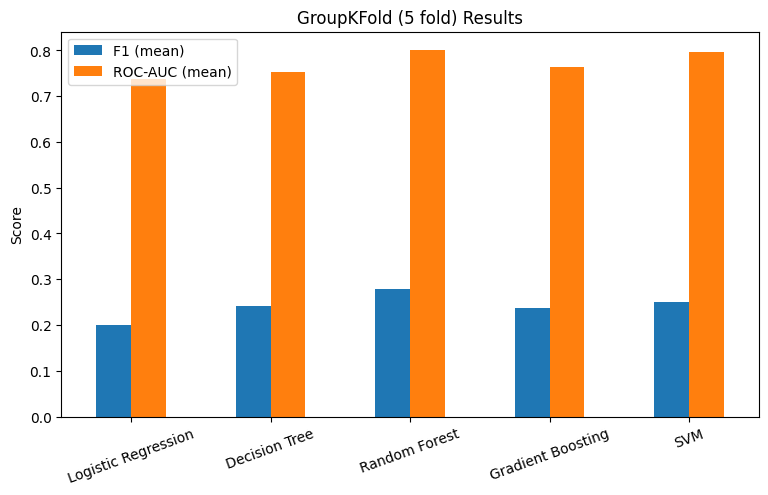

In [56]:
cv_df[['F1 (mean)', 'ROC-AUC (mean)']].plot(kind='bar', figsize=(9, 5))
plt.title("GroupKFold (5 fold) Results")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.show()

## 10. Conclusion
- RI (>= 30 kt in 24 h) is a **rare event**, so accuracy is misleading; we used Recall, F1 and ROC-AUC.
- Data was split **by storm** (GroupShuffleSplit / GroupKFold) to avoid leakage from future rows.
- Pressure was missing in many old rows, so it was filled with the median.
- The best model is the one with the highest ROC-AUC and F1 in the tables above (see the comparison and GroupKFold results).
- Important features can be seen from the Random Forest importance plot (current wind, past 24 h change, pressure etc.).
- Future work: add sea surface temperature and wind shear data, which are the real physical drivers of RI.